##Load the data


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             average_precision_score, roc_auc_score, brier_score_loss,
                             PrecisionRecallDisplay)

# Read all snapshots. Change the filename here if your upload has a different name.
df = pd.read_parquet("features.parquet")
print("Rows and columns:", df.shape)
print("Unique patients:", df["subject_id"].nunique())

Rows and columns: (725334, 101)
Unique patients: 53984


##Look at the labels


In [ ]:
# Rows show the 24-hour outcome. Columns show the 48-hour outcome.
print(pd.crosstab(df["y_24h"], df["y_48h"]))
assert (df["y_24h"] <= df["y_48h"]).all()

# Each patient-admission-time combination identifies one snapshot.
assert not df.duplicated(["subject_id", "hadm_id", "snapshot_time"]).any()
assert df["snapshot_time"].dt.strftime("%H:%M:%S").eq("08:00:00").all()

y_48h       0     1
y_24h              
0      714093  4724
1           0  6517


## 3. Split the data by patients into train, validation and test






In [ ]:
# Make one row per patient. max() tells us whether the patient ever had a positive snapshot.
patient_labels = df.groupby("subject_id")[["y_24h", "y_48h"]].max()
patient_ids = patient_labels.index

# Balance the three possible outcome groups across splits: neither, 48h only, or both.
groups = 2 * patient_labels["y_24h"] + patient_labels["y_48h"]
dev_ids, test_ids = train_test_split(patient_ids, test_size=0.20,
                                     stratify=groups, random_state=7275)
train_ids, val_ids = train_test_split(dev_ids, test_size=0.25,
                                      stratify=groups.loc[dev_ids], random_state=7275)

# Mark every snapshot belonging to each group of patients.
train = df["subject_id"].isin(train_ids)
val = df["subject_id"].isin(val_ids)
test = df["subject_id"].isin(test_ids)
assert (train.astype(int) + val.astype(int) + test.astype(int)).eq(1).all()
print("Patients in train, validation, test:", len(train_ids), len(val_ids), len(test_ids))
print("Snapshots in train, validation, test:", train.sum(), val.sum(), test.sum())

Patients in train, validation, test: 32390 10797 10797
Snapshots in train, validation, test: 436844 146091 142399


## Select Features (X) and Target Variables (y)


In [ ]:
# Remove the snapshot key and both target labels from the inputs.
X = df.drop(columns=["subject_id", "hadm_id", "snapshot_time", "y_24h", "y_48h"])
X_train, X_val, X_test = X.loc[train], X.loc[val], X.loc[test]

# Keep each outcome in its own Series. The same masks select its matching rows.
y_24h = df["y_24h"]
y_48h = df["y_48h"]
print("Training X:", X_train.shape)
print("Training y for 24 hours:", y_24h.loc[train].shape)
print("Training y for 48 hours:", y_48h.loc[train].shape)

Training X: (436844, 96)
Training y for 24 hours: (436844,)
Training y for 48 hours: (436844,)


## Prepare the Features for Model Training


In [ ]:
# Identify columns by their training data types.
numbers = X_train.select_dtypes(include="number").columns
categories = X_train.columns.difference(numbers, sort=False)
print("Categorical columns:", categories.tolist())

# Give each column type its own preparation steps.
numeric_steps = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
category_steps = make_pipeline(SimpleImputer(strategy="most_frequent"),
                               OneHotEncoder(handle_unknown="ignore"))
prep = make_column_transformer((numeric_steps, numbers), (category_steps, categories))

# Learn the rules once on training data. Reuse them for validation and test.
X_train_ready = prep.fit_transform(X_train)
X_val_ready = prep.transform(X_val)
X_test_ready = prep.transform(X_test)
print("Training X after encoding:", X_train_ready.shape)

Categorical columns: ['admission_type', 'admission_location', 'careunit', 'curr_service']
Training X after encoding: (436844, 154)


## Train the 24-Hour and 48-Hour Prediction Models


In [ ]:
# Learn which features predict a transfer within 24 hours.
model_24h = LogisticRegression(max_iter=1000)
model_24h.fit(X_train_ready, y_24h.loc[train])

# Repeat with the 48-hour outcome.
model_48h = LogisticRegression(max_iter=1000)
model_48h.fit(X_train_ready, y_48h.loc[train])
print("Both models are trained.")

Both models are trained.


## Define the Watchlist Evaluation Function


In [ ]:
# Use the same calculation for both horizons and both evaluation sets.
def watchlist_results(actual, risk):
    # Keep each probability on the same row as its observed outcome.
    scores = pd.Series(risk, index=actual.index)
    size = int(np.ceil(0.10 * len(scores)))
    top_rows = scores.nlargest(size).index
    flagged = scores.index.isin(top_rows)

    # Count the actual positives among the flagged snapshots.
    hits = actual.loc[top_rows].sum()
    results = {
        "Flagged": size, "True positives": hits,
        "Precision@10%": hits / size, "Recall@10%": hits / actual.sum(),
        "Positive rate": actual.mean(), "AP": average_precision_score(actual, risk),
        "ROC AUC": roc_auc_score(actual, risk), "Brier": brier_score_loss(actual, risk),
    }
    return results, flagged

## Evaluate the 24-Hour and 48-Hour Models on the Validation Set

In [ ]:
# Column 1 is the estimated probability of a positive outcome.
val_risk_24h = model_24h.predict_proba(X_val_ready)[:, 1]
val_risk_48h = model_48h.predict_proba(X_val_ready)[:, 1]

# Each horizon has its own scores, labels, and watchlist.
val_24h, _ = watchlist_results(y_24h.loc[val], val_risk_24h)
val_48h, _ = watchlist_results(y_48h.loc[val], val_risk_48h)
print(pd.DataFrame({"24 hours": val_24h, "48 hours": val_48h}).round(4))

                  24 hours    48 hours
Flagged         14610.0000  14610.0000
True positives    499.0000    788.0000
Precision@10%       0.0342      0.0539
Recall@10%          0.3898      0.3545
Positive rate       0.0088      0.0152
AP                  0.0394      0.0550
ROC AUC             0.7531      0.7417
Brier               0.0086      0.0148


**Read the table.** Compare average precision (AP) with the positive rate for that horizon. ROC AUC measures ranking across positives and negatives. Brier score measures squared probability error, where smaller is better.

## Evaluate the 24-Hour and 48-Hour Models on the Test Set


In [ ]:
# Score the test rows and keep the watchlist flags for the confusion matrices.
test_risk_24h = model_24h.predict_proba(X_test_ready)[:, 1]
test_risk_48h = model_48h.predict_proba(X_test_ready)[:, 1]
test_24h, flags_24h = watchlist_results(y_24h.loc[test], test_risk_24h)
test_48h, flags_48h = watchlist_results(y_48h.loc[test], test_risk_48h)
print(pd.DataFrame({"24 hours": test_24h, "48 hours": test_48h}).round(4))

                  24 hours    48 hours
Flagged         14240.0000  14240.0000
True positives    516.0000    824.0000
Precision@10%       0.0362      0.0579
Recall@10%          0.3939      0.3605
Positive rate       0.0092      0.0161
AP                  0.0517      0.0651
ROC AUC             0.7551      0.7469
Brier               0.0089      0.0154


## Visualize and Interpret Model Performance


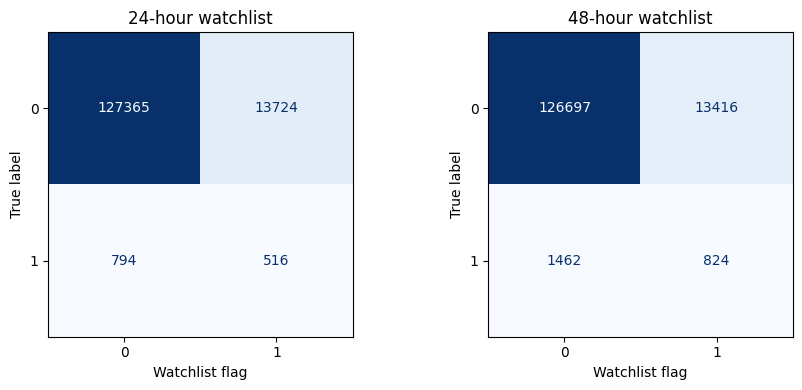

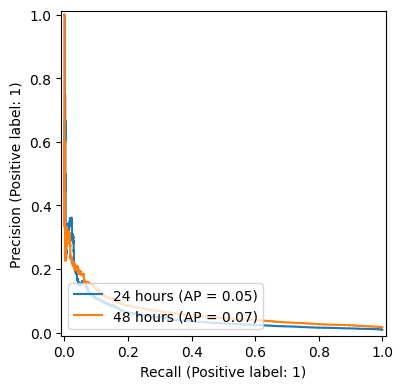

In [ ]:
# Show the watchlist confusion matrix for each horizon.
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, hours, actual, flags in [(axes[0], 24, y_24h.loc[test], flags_24h),
                                  (axes[1], 48, y_48h.loc[test], flags_48h)]:
    matrix = confusion_matrix(actual, flags, labels=[0, 1])
    ConfusionMatrixDisplay(matrix).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{hours}-hour watchlist")
    ax.set_xlabel("Watchlist flag")
plt.tight_layout()
plt.show()

# Compare precision and recall across all probability cutoffs.
fig, ax = plt.subplots(figsize=(6, 4))
PrecisionRecallDisplay.from_predictions(y_24h.loc[test], test_risk_24h, name="24 hours", ax=ax)
PrecisionRecallDisplay.from_predictions(y_48h.loc[test], test_risk_48h, name="48 hours", ax=ax)
plt.tight_layout()
plt.show()

## Compare the ROC Curves for the 24-Hour and 48-Hour Models

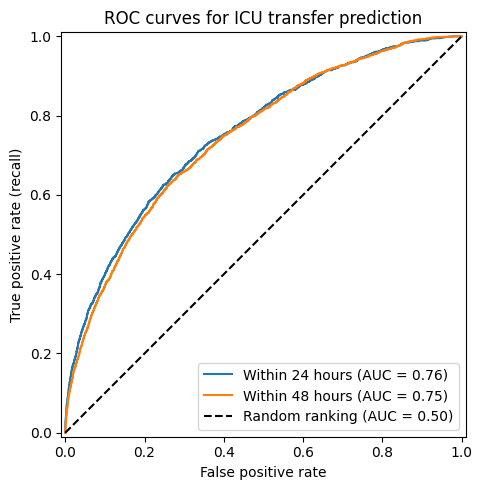

In [ ]:
from sklearn.metrics import RocCurveDisplay

# Draw both ROC curves on the same graph.
fig, ax = plt.subplots(figsize=(6, 5))

# Compare the actual 24-hour labels with the 24-hour predicted probabilities.
RocCurveDisplay.from_predictions(
    y_24h.loc[test], test_risk_24h, name="Within 24 hours", ax=ax
)

# Repeat for the 48-hour model using the same test snapshots.
RocCurveDisplay.from_predictions(
    y_48h.loc[test], test_risk_48h, name="Within 48 hours", ax=ax
)

# The diagonal shows the expected performance of random ranking.
ax.plot([0, 1], [0, 1], "k--", label="Random ranking (AUC = 0.50)")
ax.set_title("ROC curves for ICU transfer prediction")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Compare the Top 10 Features in the 24-Hour and 48-Hour Models

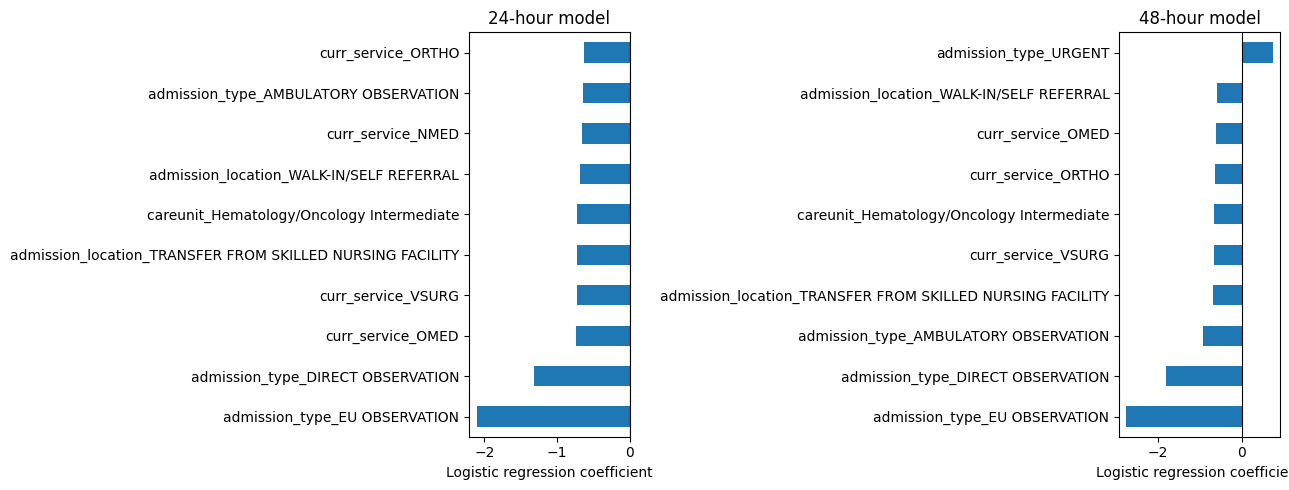

In [ ]:
# Get the feature names after preprocessing and one-hot encoding.
feature_names = prep.get_feature_names_out()

# Plot the 24-hour and 48-hour models side by side.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model, title, ax in zip(
    [model_24h, model_48h], ["24-hour model", "48-hour model"], axes
):
    # Match each feature name to its logistic regression coefficient.
    coef = pd.Series(model.coef_[0], index=feature_names)

    # Remove preprocessing prefixes to make the labels easier to read.
    coef.index = coef.index.str.split("__", n=1).str[-1]

    # Select the 10 largest coefficients by magnitude, keeping their signs.
    top_names = coef.abs().nlargest(10).index
    top = coef.loc[top_names].sort_values()

    # Bars to the right are positive. Bars to the left are negative.
    top.plot.barh(ax=ax)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Logistic regression coefficient")

plt.tight_layout()
plt.show()

## Display the Top 10 Highest-Risk Patient Snapshots

In [ ]:
# Identify each test snapshot by patient, admission, and time.
out = df.loc[test, ["subject_id", "hadm_id", "snapshot_time"]].copy()

# Add the predicted probabilities from the two trained models.
out["risk_24h"] = test_risk_24h
out["risk_48h"] = test_risk_48h

# Add the observed outcomes: 1 = ICU transfer within that window, 0 = none.
out["actual_24h"] = y_24h.loc[test]
out["actual_48h"] = y_48h.loc[test]

# Sort by 24-hour risk and display the 10 highest-risk snapshots.
out.sort_values("risk_24h", ascending=False).head(10).round(3)

,subject_id,hadm_id,snapshot_time,risk_24h,risk_48h,actual_24h,actual_48h
594700,18207287,29203666,2184-11-02 08:00:00,0.880,0.882,1,1
159682,12223437,27682564,2153-02-27 08:00:00,0.794,0.786,0,0
278624,13814884,21637411,2146-12-04 08:00:00,0.727,0.691,1,1
406616,15587744,26588076,2169-10-06 08:00:00,0.659,0.691,1,1
64779,10930322,23719755,2132-03-16 08:00:00,0.655,0.722,0,0
584699,18069196,29992506,2201-08-15 08:00:00,0.609,0.530,1,1
334881,14591481,20754616,2163-10-14 08:00:00,0.602,0.676,0,0
446479,16141152,27930084,2193-01-15 08:00:00,0.600,0.596,0,0
663295,19155768,20601043,2181-04-19 08:00:00,0.585,0.646,0,0
194473,12686318,25196475,2153-02-18 08:00:00,0.575,0.641,1,1
